In [1]:

import glob
import numpy as np
import plotter_config as pc
import sim_name_remap as map
import netCDF4 as nc4
import os
import datetime as dt
from scipy.interpolate import interp1d
import pickle as pkl
import matplotlib.tri as tri
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import datetime
from astropy.time import Time
import utils


In [2]:

def get_mean_prof(SAVEDIR, sim, var_lab, plot_lev, profvar, conv_dom, prs_grid, date0, date1):
    
    SAVEFILES = SAVEDIR + sim + '_' + var_lab + '_' + str(int(plot_lev)) + '_max' + profvar + 'prof_' + str(conv_dom)
    SAVEFILES = sorted(glob.glob(SAVEFILES[:-1] + '*.pkl'))  # This should not be necessary but the glob function is resisting the closing ] from being found...

    fileind0 = next(i for i, s in enumerate(SAVEFILES) if date0 in s)  
    fileind1 = next(i for i, s in enumerate(SAVEFILES) if date1 in s)

    SAVEFILES = SAVEFILES[fileind0:fileind1+1]
    
    varprofs = []
    prsprofs = []
    prs_plot  = []
    
    for FILE in SAVEFILES:
        with open(FILE, 'rb') as f: 
            varprof, plev = pkl.load(f)
    
        varprofs.extend(varprof)
        prsprofs.extend(plev)
    
    var_mean = []
    
    # For each pressure bin, grab all the points 
    for p in range(len(prs_grid)-1):
    
        curr_pmin = prs_grid[p]
        curr_pmax = prs_grid[p+1]
        prs_plot.append(np.mean([curr_pmin, curr_pmax]))
        curr_var = []
    
        for pt in range(len(varprofs)):
            
            if prsprofs[pt] >= curr_pmin and prsprofs[pt] <= curr_pmax: curr_var.append(varprofs[pt])
    
        if len(curr_var) > 0: var_mean.append(np.mean(curr_var))
        else: var_mean.append(-999)

    return var_mean, prs_plot


In [3]:

sims = ['2022_E5-strong','2022_E5-weak','2022_M2-strong','2022_M2-weak','2022_FreeRun']  # FreeRun is a blind squirrel that found a nut at a poor time
var_lab = 'ZMMU'  # The variable used to locate the max value
plot_lev = 250.
profvars = ['ZMMU','CO']  # The variable which profiles are calculated for
conv_dom = [110,122,36,42]
SAVEDIR = '/glade/u/home/wsmith/NudgeComparison_scripts/vars/'
prs_grid = np.arange(0,1001,50)
date0 = '20220818_06Z'
date1 = '20220818_18Z'


In [4]:

def convdom_prof_plot(ax, sims, var_lab, plot_lev, profvar, conv_dom, SAVEDIR, prs_grid, date0, date1, let):
    
    var_mean0, prs_plot = get_mean_prof(SAVEDIR, sims[0], var_lab, plot_lev, profvar, conv_dom, prs_grid, date0, date1)
    var_mean1, prs_plot = get_mean_prof(SAVEDIR, sims[1], var_lab, plot_lev, profvar, conv_dom, prs_grid, date0, date1)
    var_mean2, prs_plot = get_mean_prof(SAVEDIR, sims[2], var_lab, plot_lev, profvar, conv_dom, prs_grid, date0, date1)
    var_mean3, prs_plot = get_mean_prof(SAVEDIR, sims[3], var_lab, plot_lev, profvar, conv_dom, prs_grid, date0, date1)
    #var_mean4, prs_plot = get_mean_prof(SAVEDIR, sims[4], var_lab, plot_lev, profvar, conv_dom, prs_grid, date0, date1)
    
    ax.plot(var_mean0, prs_plot, color='red', label=sims[0], linewidth=3)
    ax.plot(var_mean1, prs_plot, color='orange', label=sims[1], linewidth=3)
    ax.plot(var_mean2, prs_plot, color='blue', label=sims[2], linewidth=3)
    ax.plot(var_mean3, prs_plot, color='cyan', label=sims[3], linewidth=3)
    #ax.plot(var_mean4, prs_plot, color='gray', label=sims[4], linewidth=3)    
    
    if profvar == 'ZMMU': print(prs_plot[np.argmax(var_mean0)], prs_plot[np.argmax(var_mean1)], prs_plot[np.argmax(var_mean2)], prs_plot[np.argmax(var_mean3)], prs_plot[np.argmax(var_mean3)])
    
    # These automatically snap to the max value on the profile, but we want to keep them consistent between plots so we do an uglier bypass
    #ax.plot([0,10000],[prs_plot[np.argmax(var_mean0)],prs_plot[np.argmax(var_mean0)]],color='red',linestyle=':',linewidth=1)
    #ax.plot([0,10000],[prs_plot[np.argmax(var_mean1)],prs_plot[np.argmax(var_mean1)]],color='orange',linestyle=':',linewidth=1)
    #ax.plot([0,10000],[prs_plot[np.argmax(var_mean2)],prs_plot[np.argmax(var_mean2)]],color='blue',linestyle=':',linewidth=1)
    
    ax.plot([0,10000],[275,275],color='red',linestyle=':',linewidth=1)
    ax.plot([0,10000],[375,375] ,color='orange',linestyle=':',linewidth=1)
    ax.plot([0,10000],[525,525],color='blue',linestyle=':',linewidth=1)
    ax.plot([0,10000],[425,425],color='cyan',linestyle=':',linewidth=1)
    #ax.plot([0,10000],[0,0],color='gray',linestyle=':',linewidth=1)    
    
    if profvar == 'CO': ax.set_xlim(30,250)
    if profvar == 'ZMMU': ax.set_xlim(0,220)
    ax.set_ylim(1000,100)
    ax.set_yscale('log')
    ax.set_ylabel('Pressure (hPa)')
    ax.set_xlabel(profvar + ' (' + pc.var_info[profvar]['unit'] + ')')
    
    if profvar == 'ZMMU': 
        with open('/glade/u/home/wsmith/NudgeComparison_scripts/Analysis_Files/M2_CMFMC.pkl', 'rb') as f:
            CMFMC_meanprof, M2prs = pkl.load(f)
        CMFMC_meanprof[CMFMC_meanprof > 100000] = np.nan
        ax.plot(CMFMC_meanprof, M2prs, linewidth=2, color='blue', linestyle='--', label='MERRA-2 CMFMC')
    
        with open('/glade/u/home/wsmith/NudgeComparison_scripts/Analysis_Files/E5_MUMF.pkl', 'rb') as f:
            MUMF_meanprof, E5prs = pkl.load(f)
        ax.plot(MUMF_meanprof*0.2, E5prs, linewidth=2, color='red', linestyle='--', label='0.2*ERA5 MUMF')
    
    yticks = [100,200,300,400,600,1000]
    ax.set_yticks(yticks)
    ax.set_yticklabels([str(p) for p in yticks])
    
    if profvar == 'ZMMU': ax.legend()
    
    #plt.plot([0,300],[175,175], color='k', linewidth=0.5)  # Horizontal line
    
    ax.set_title(let + profvar + ' at max ' + str(int(plot_lev)) + 'hPa ' + var_lab + ' in ' + str(conv_dom))
    #plt.figtext(0.2,0.13,'Date Range: ' + date0 + '-' + date1)



275.0 375.0 525.0 425.0 425.0


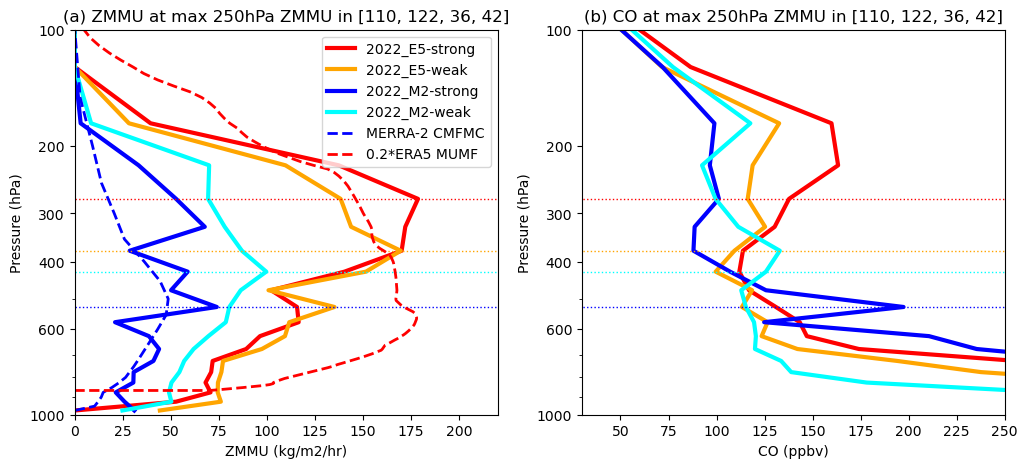

In [5]:

fig = plt.figure(figsize=(12,5))
ax1 = fig.add_subplot(121)
ax2 = fig.add_subplot(122)

convdom_prof_plot(ax1, sims, var_lab, plot_lev, profvars[0], conv_dom, SAVEDIR, prs_grid, date0, date1, '(a) ')
convdom_prof_plot(ax2, sims, var_lab, plot_lev, profvars[1], conv_dom, SAVEDIR, prs_grid, date0, date1, '(b) ')

plt.savefig('/glade/u/home/wsmith/NudgeComparison_scripts/plots/Figure8.png', dpi=300)
plt.savefig('/glade/u/home/wsmith/NudgeComparison_scripts/plots/Figure8.pdf', dpi=300)
